# RQ1 — Temporal alignment

Inputs: `../metrics/pre_cutoff.csv` and `../metrics/post_cutoff.csv` (relative to this notebook; `results/rq1/metrics/` when run from the repository root).

Outputs (displayed inline; no files are written): per-model paired tests of post- vs. pre-cutoff Macro-F1 with Holm-adjusted p-values and effect sizes, and a figure of the per-project differences (post − pre).

Run: *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pingouin as pg
from IPython.display import display


PROJECT_COLUMN = "project"

PRE_CUTOFF_PATH = Path("../metrics/pre_cutoff.csv")
POST_CUTOFF_PATH = Path("../metrics/post_cutoff.csv")

if not PRE_CUTOFF_PATH.exists():
    PRE_CUTOFF_PATH = Path("results/rq1/metrics/pre_cutoff.csv")

if not POST_CUTOFF_PATH.exists():
    POST_CUTOFF_PATH = Path("results/rq1/metrics/post_cutoff.csv")

if not PRE_CUTOFF_PATH.exists():
    raise FileNotFoundError("Could not find pre_cutoff.csv.")

if not POST_CUTOFF_PATH.exists():
    raise FileNotFoundError("Could not find post_cutoff.csv.")


df_pre_raw = pd.read_csv(
    PRE_CUTOFF_PATH,
    index_col=PROJECT_COLUMN,
)

df_post_raw = pd.read_csv(
    POST_CUTOFF_PATH,
    index_col=PROJECT_COLUMN,
)


if df_pre_raw.index.duplicated().any():
    duplicates = (
        df_pre_raw.index[df_pre_raw.index.duplicated()]
        .astype(str)
        .tolist()
    )
    raise ValueError(
        f"Duplicate project identifiers in pre-cutoff data: {duplicates}"
    )

if df_post_raw.index.duplicated().any():
    duplicates = (
        df_post_raw.index[df_post_raw.index.duplicated()]
        .astype(str)
        .tolist()
    )
    raise ValueError(
        f"Duplicate project identifiers in post-cutoff data: {duplicates}"
    )


models_only_pre = [
    column
    for column in df_pre_raw.columns
    if column not in df_post_raw.columns
]

models_only_post = [
    column
    for column in df_post_raw.columns
    if column not in df_pre_raw.columns
]

common_columns = df_pre_raw.columns.intersection(
    df_post_raw.columns
)

if len(common_columns) == 0:
    raise ValueError(
        "No common model columns were found between the two datasets."
    )


models = list(common_columns)

for column in models:
    pre_numeric = pd.to_numeric(
        df_pre_raw[column],
        errors="coerce",
    )
    post_numeric = pd.to_numeric(
        df_post_raw[column],
        errors="coerce",
    )

    pre_observed = df_pre_raw[column].notna()
    post_observed = df_post_raw[column].notna()

    if (
        pre_observed.any()
        and not pre_numeric.loc[pre_observed].notna().all()
    ):
        raise ValueError(
            f"Pre-cutoff model column '{column}' contains non-numeric values."
        )

    if (
        post_observed.any()
        and not post_numeric.loc[post_observed].notna().all()
    ):
        raise ValueError(
            f"Post-cutoff model column '{column}' contains non-numeric values."
        )

    df_pre_raw[column] = pre_numeric
    df_post_raw[column] = post_numeric


projects_only_pre = (
    df_pre_raw.index
    .difference(df_post_raw.index)
    .tolist()
)

projects_only_post = (
    df_post_raw.index
    .difference(df_pre_raw.index)
    .tolist()
)

common_projects = df_pre_raw.index.intersection(
    df_post_raw.index
)


df_pre = df_pre_raw.loc[
    common_projects,
    models,
].copy()

df_post = df_post_raw.loc[
    common_projects,
    models,
].copy()


incomplete_mask = (
    df_pre.isna().any(axis=1)
    | df_post.isna().any(axis=1)
)

removed_projects = (
    common_projects[incomplete_mask.to_numpy()]
    .astype(str)
    .tolist()
)

df_pre = df_pre.loc[~incomplete_mask].copy()
df_post = df_post.loc[~incomplete_mask].copy()

if len(df_pre) < 3:
    raise ValueError(
        "Fewer than three complete paired projects remain."
    )


print(f"Pre-cutoff source: {PRE_CUTOFF_PATH}")
print(f"Post-cutoff source: {POST_CUTOFF_PATH}")
print(f"Complete paired projects retained: {len(df_pre)}")
print(f"Detected models ({len(models)}): {models}")

if removed_projects:
    print(
        "Projects removed by complete-case paired filtering: "
        f"{removed_projects}"
    )

if models_only_pre:
    print(
        "Columns present only in pre-cutoff data: "
        f"{models_only_pre}"
    )

if models_only_post:
    print(
        "Columns present only in post-cutoff data: "
        f"{models_only_post}"
    )

if projects_only_pre:
    print(
        "Projects present only in pre-cutoff data: "
        f"{projects_only_pre}"
    )

if projects_only_post:
    print(
        "Projects present only in post-cutoff data: "
        f"{projects_only_post}"
    )

display(df_pre.head())
display(df_post.head())


def _round_small(frame, decimals):
    """Round for display; nonzero values that round to 0 are shown as <0.001."""
    rounded = frame.round(decimals)
    out = rounded.astype(object)
    for column in frame.select_dtypes("number").columns:
        tiny = (frame[column] != 0) & (rounded[column] == 0)
        out.loc[tiny, column] = "<0.001"
    return out


Pre-cutoff source: ..\metrics\pre_cutoff.csv
Post-cutoff source: ..\metrics\post_cutoff.csv
Complete paired projects retained: 30
Detected models (8): ['Gemma 3', 'GPT-OSS 20B', 'Granite 3.3 8B', 'Llama 3.2 11B', 'Magistral 24B', 'Mistral Small 3.2 24B', 'Phi-4 RP 14B', 'QwQ 32B']


,Gemma 3,GPT-OSS 20B,Granite 3.3 8B,Llama 3.2 11B,Magistral 24B,Mistral Small 3.2 24B,Phi-4 RP 14B,QwQ 32B
project,,,,,,,,
cargo/clap,0.417343,0.548896,0.337526,0.326162,0.426996,0.522409,0.366256,0.698765
go/google-cloud-go,0.351706,0.468451,0.311360,0.217493,0.371947,0.389580,0.361180,0.493491
npm/angular,0.154877,0.325053,0.251238,0.122198,0.293404,0.280069,0.238904,0.369469
npm/ant-design,0.296033,0.357966,0.282122,0.243352,0.310543,0.330106,0.262403,0.380517
npm/biome,0.472405,0.511996,0.345657,0.202602,0.346072,0.350707,0.420968,0.503426


,Gemma 3,GPT-OSS 20B,Granite 3.3 8B,Llama 3.2 11B,Magistral 24B,Mistral Small 3.2 24B,Phi-4 RP 14B,QwQ 32B
project,,,,,,,,
cargo/clap,0.494893,0.565305,0.354337,0.321283,0.508135,0.520770,0.423460,0.641148
go/google-cloud-go,0.355742,0.400777,0.273254,0.252781,0.430277,0.400305,0.261780,0.494286
npm/angular,0.233311,0.425863,0.258595,0.146850,0.316509,0.249811,0.188025,0.379639
npm/ant-design,0.301265,0.408498,0.243059,0.177513,0.335377,0.297900,0.336391,0.410506
npm/biome,0.333307,0.466246,0.334434,0.211444,0.386117,0.428901,0.368909,0.477878


## Analysis functions

In [2]:
from scipy.stats import shapiro, t, ttest_rel


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    absolute_effect = abs(float(effect))

    if route == "parametric":
        if absolute_effect < 0.2:
            return "Negligible"
        if absolute_effect < 0.5:
            return "Small"
        if absolute_effect < 0.8:
            return "Medium"
        return "Large"

    if absolute_effect < 0.1:
        return "Negligible"
    if absolute_effect < 0.3:
        return "Small"
    if absolute_effect < 0.5:
        return "Medium"
    return "Large"


def run_temporal_alignment_analysis(
    pre_data,
    post_data,
    alpha=0.05,
):
    if not pre_data.index.equals(post_data.index):
        raise ValueError("Pre and post project indices are not aligned.")
    if not pre_data.columns.equals(post_data.columns):
        raise ValueError("Pre and post model columns are not aligned.")

    differences = post_data - pre_data

    shapiro_rows = []
    for model in differences.columns:
        statistic, p_value = shapiro(differences[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(differences[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    result_rows = []

    for model in differences.columns:
        pre_values = pre_data[model].to_numpy()
        post_values = post_data[model].to_numpy()
        delta = differences[model]
        n = len(delta)

        mean_pre = float(np.mean(pre_values))
        mean_post = float(np.mean(post_values))
        mean_delta = float(delta.mean())
        sd_delta = float(delta.std(ddof=1))

        if route == "parametric":
            test_statistic, p_raw = ttest_rel(
                post_values,
                pre_values,
            )

            if np.allclose(post_values - pre_values, 0):
                hedges_g = 0.0
            else:
                hedges_g = pg.compute_effsize(
                    post_values,
                    pre_values,
                    paired=True,
                    eftype="hedges",
                )

            standard_error = delta.sem()
            if standard_error == 0:
                ci_lower = mean_delta
                ci_upper = mean_delta
            else:
                ci_lower, ci_upper = t.interval(
                    0.95,
                    df=n - 1,
                    loc=mean_delta,
                    scale=standard_error,
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
            effect = float(hedges_g)

        else:
            if np.allclose(post_values - pre_values, 0):
                test_statistic = 0.0
                p_raw = 1.0
                rbc = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    post_values,
                    pre_values,
                    alternative="two-sided",
                ).iloc[0]
                test_statistic = float(wilcoxon["W_val"])
                p_raw = float(wilcoxon["p_val"])
                rbc = float(wilcoxon["RBC"])

            ci_lower = np.nan
            ci_upper = np.nan
            statistic_name = "W"
            effect_name = "RBC"
            effect = rbc

        result_rows.append({
            "Model": model,
            "N": n,
            "Mean Pre": mean_pre,
            "Mean Post": mean_post,
            "Mean Delta": mean_delta,
            "SD Delta": sd_delta,
            "CI95 Lower": ci_lower,
            "CI95 Upper": ci_upper,
            "Statistic name": statistic_name,
            "Statistic": float(test_statistic),
            "p_raw": float(p_raw),
            "Effect name": effect_name,
            "Effect": effect,
        })

    results = pd.DataFrame(result_rows).set_index("Model")

    reject, corrected_p = pg.multicomp(
        results["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    results["p_Holm"] = corrected_p
    results["Significant"] = reject
    results["Effect magnitude"] = results["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    improvement_rows = []
    for model in differences.columns:
        delta = differences[model]
        improved = int((delta > 0).sum())
        worsened = int((delta < 0).sum())
        unchanged = int((delta == 0).sum())
        total = len(delta)

        improvement_rows.append({
            "Model": model,
            "Improved (n)": improved,
            "Improved (%)": 100 * improved / total,
            "Worsened (n)": worsened,
            "Worsened (%)": 100 * worsened / total,
            "Unchanged (n)": unchanged,
            "Unchanged (%)": 100 * unchanged / total,
        })

    improvement = pd.DataFrame(improvement_rows).set_index("Model")

    print("PAIRED DIFFERENCE NORMALITY")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    print("HOLM-CORRECTED MODEL-LEVEL RESULTS")

    result_display = results.copy()
    result_display["p_raw"] = result_display["p_raw"].map(
        _format_p_plain
    )
    result_display["p_Holm"] = result_display["p_Holm"].map(
        _format_p_plain
    )
    display(_round_small(result_display, {
        "Mean Pre": 4,
        "Mean Post": 4,
        "Mean Delta": 4,
        "SD Delta": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Statistic": 4,
        "Effect": 4,
    }))

    print("PROJECT-LEVEL DIRECTION OF CHANGE")
    display(_round_small(improvement, {
        "Improved (%)": 1,
        "Worsened (%)": 1,
        "Unchanged (%)": 1,
    }))

    return {
        "route": route,
        "differences": differences,
        "shapiro": shapiro_results,
        "results": results,
        "improvement": improvement,
        "alpha": alpha,
    }


## Run the analysis

In [3]:
rq1_analysis = run_temporal_alignment_analysis(
    pre_data=df_pre,
    post_data=df_post,
)

PAIRED DIFFERENCE NORMALITY


,N,W,p,Normality not rejected
Model,,,,
Gemma 3,30,0.9757,.7039,True
GPT-OSS 20B,30,0.9674,.4710,True
Granite 3.3 8B,30,0.9558,.2403,True
Llama 3.2 11B,30,0.9587,.2872,True
Magistral 24B,30,0.9622,.3522,True
Mistral Small 3.2 24B,30,0.9616,.3410,True
Phi-4 RP 14B,30,0.9627,.3633,True
QwQ 32B,30,0.9448,.1226,True


SELECTED ROUTE: parametric
HOLM-CORRECTED MODEL-LEVEL RESULTS


,N,Mean Pre,Mean Post,Mean Delta,SD Delta,CI95 Lower,CI95 Upper,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Effect magnitude
Model,,,,,,,,,,,,,,,
Gemma 3,30,0.3483,0.366,0.0177,0.1171,-0.0261,0.0614,t,0.8262,.4155,Hedges' g,0.1827,1.0000,False,Negligible
GPT-OSS 20B,30,0.4434,0.4676,0.0243,0.12,-0.0205,0.0691,t,1.1078,.2771,Hedges' g,0.243,1.0000,False,Small
Granite 3.3 8B,30,0.2979,0.3076,0.0097,0.0963,-0.0262,0.0457,t,0.5544,.5835,Hedges' g,0.1235,1.0000,False,Negligible
Llama 3.2 11B,30,0.245,0.2504,0.0055,0.0799,-0.0244,0.0353,t,0.3744,.7108,Hedges' g,0.0682,1.0000,False,Negligible
Magistral 24B,30,0.3926,0.4094,0.0168,0.1157,-0.0264,0.06,t,0.7941,.4336,Hedges' g,0.1597,1.0000,False,Negligible
Mistral Small 3.2 24B,30,0.384,0.4065,0.0225,0.1123,-0.0194,0.0645,t,1.0993,.2807,Hedges' g,0.2535,1.0000,False,Small
Phi-4 RP 14B,30,0.3295,0.329,-0.0005,0.1336,-0.0504,0.0494,t,-0.0206,.9837,Hedges' g,-0.0054,1.0000,False,Negligible
QwQ 32B,30,0.4735,0.4743,0.0007,0.125,-0.0459,0.0474,t,0.0328,.9740,Hedges' g,0.0071,1.0000,False,Negligible


PROJECT-LEVEL DIRECTION OF CHANGE


,Improved (n),Improved (%),Worsened (n),Worsened (%),Unchanged (n),Unchanged (%)
Model,,,,,,
Gemma 3,17,56.7,13,43.3,0,0.0
GPT-OSS 20B,17,56.7,13,43.3,0,0.0
Granite 3.3 8B,17,56.7,13,43.3,0,0.0
Llama 3.2 11B,16,53.3,14,46.7,0,0.0
Magistral 24B,18,60.0,12,40.0,0,0.0
Mistral Small 3.2 24B,14,46.7,16,53.3,0,0.0
Phi-4 RP 14B,16,53.3,14,46.7,0,0.0
QwQ 32B,14,46.7,16,53.3,0,0.0


## Figure

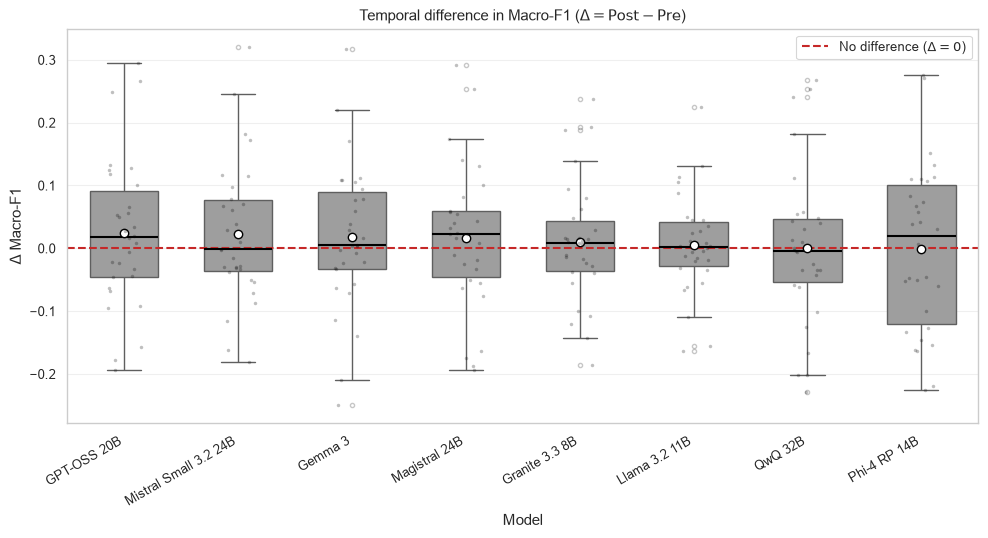

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

differences = rq1_analysis["differences"]
model_order = differences.mean().sort_values(ascending=False).index

plot_data = (
    differences[model_order]
    .rename_axis("project")
    .reset_index()
    .melt(
        id_vars="project",
        var_name="Model",
        value_name="Delta",
    )
)

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.1,
    rc={"grid.alpha": 0.3},
)

figure_width = max(8, 1.25 * len(model_order))
fig, ax = plt.subplots(figsize=(figure_width, 5.5))

sns.boxplot(
    data=plot_data,
    x="Model",
    y="Delta",
    order=model_order,
    color="#9E9E9E",
    width=0.6,
    showmeans=True,
    medianprops={"linewidth": 1.5, "color": "black"},
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 6,
    },
    flierprops={
        "marker": "o",
        "markersize": 3,
        "alpha": 0.35,
    },
    ax=ax,
)

sns.stripplot(
    data=plot_data,
    x="Model",
    y="Delta",
    order=model_order,
    color="black",
    alpha=0.25,
    size=2.5,
    jitter=0.15,
    ax=ax,
)

ax.axhline(
    0,
    color="#C62828",
    linestyle="--",
    linewidth=1.5,
    label=r"No difference ($\Delta=0$)",
)

ax.set_title(
    r"Temporal difference in Macro-F1 ($\Delta=\mathrm{Post}-\mathrm{Pre}$)"
)
ax.set_xlabel("Model")
ax.set_ylabel(r"$\Delta$ Macro-F1")
ax.tick_params(axis="x", rotation=30)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")
ax.legend(loc="best", frameon=True)

fig.tight_layout()
plt.show()
